In [4]:
import os
import numpy as np
from PIL import Image

TRAIN_DIR = "/kaggle/input/datasets/salader/dogsvscats/train"
IMG_SIZE = (128, 128)
SAMPLE_SIZE = 200  # per class

def load_images(folder, label, n):
    files = os.listdir(folder)[:n]
    data, labels = [], []

    for fname in files:
        img = Image.open(
            os.path.join(folder, fname)
        ).convert("RGB").resize(IMG_SIZE)

        data.append(np.array(img))
        labels.append(label)

    return data, labels

cat_imgs, cat_labels = load_images(
    os.path.join(TRAIN_DIR, "cats"), "cat", SAMPLE_SIZE
)

dog_imgs, dog_labels = load_images(
    os.path.join(TRAIN_DIR, "dogs"), "dog", SAMPLE_SIZE
)

images = np.array(cat_imgs + dog_imgs)
true_labels = cat_labels + dog_labels

print(images.shape)

(400, 128, 128, 3)


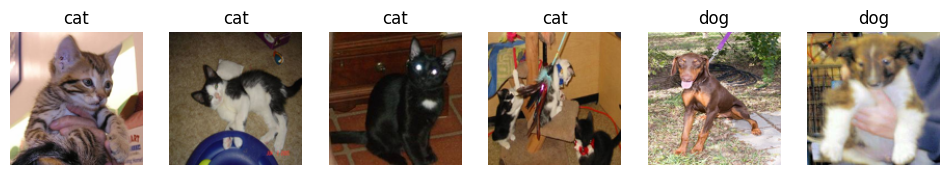

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 6, figsize=(12, 2))

for i in range(6):
    axes[i].imshow(images[i * 65])
    axes[i].set_title(true_labels[i * 65])
    axes[i].axis("off")

plt.show()

In [6]:
X = images.reshape(len(images), -1) / 255.0
print(X.shape)

(400, 49152)


In [7]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X)

KMeans(n_clusters=2, n_init=10, random_state=42)

In [8]:
predicted_clusters = kmeans.predict(X)
import pandas as pd
print(pd.Series(predicted_clusters).value_counts())

1    207
0    193
Name: count, dtype: int64


In [9]:
comparison = pd.crosstab(predicted_clusters, true_labels)
print(comparison)

col_0  cat  dog
row_0          
0       92  101
1      108   99


In [10]:
print("Accuracy:", (sum((predicted_clusters == 0) == (np.array(true_labels) == "dog")) / len(true_labels)) * 100, "%")

Accuracy: 52.25 %


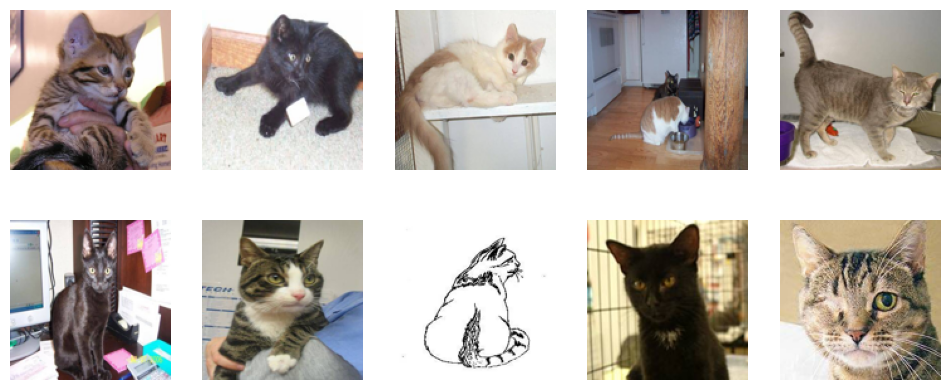

In [12]:
import matplotlib.pyplot as plt

cluster_1_images = images[predicted_clusters == 1]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(10):
    axes[i // 5, i % 5].imshow(cluster_0_images[i])
    axes[i // 5, i % 5].axis("off")

plt.show()

In [13]:
print(pd.Series(np.array(true_labels)[predicted_clusters == 0]).value_counts())

dog    101
cat     92
Name: count, dtype: int64


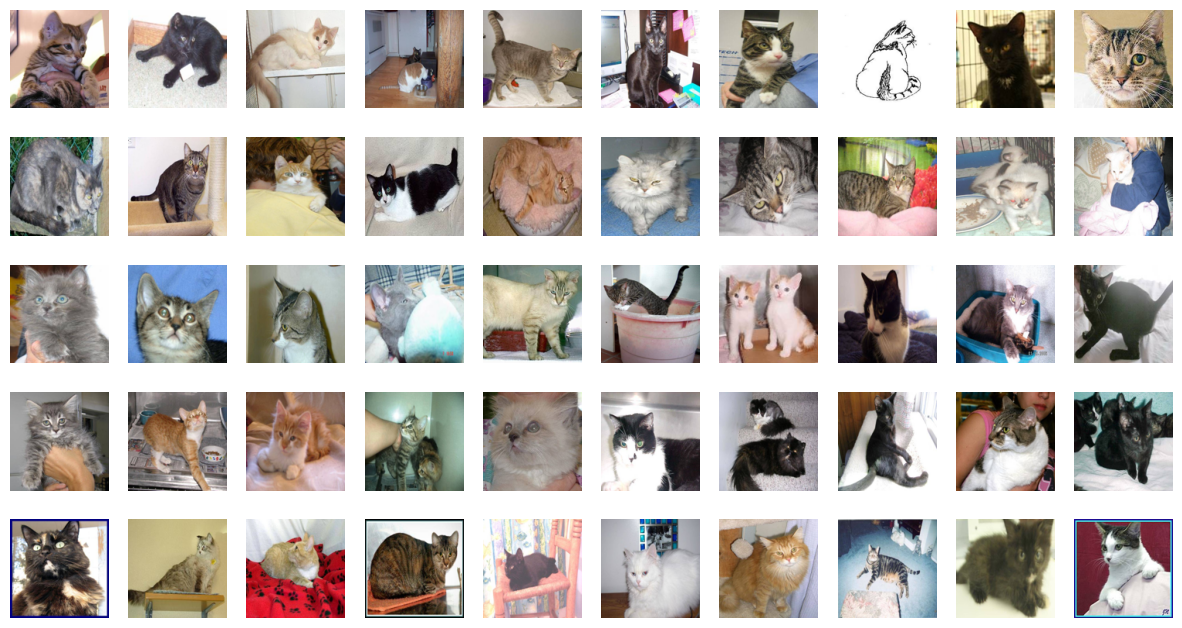

In [14]:
import matplotlib.pyplot as plt

cluster_0_images = images[predicted_clusters == 0]

fig, axes = plt.subplots(5, 10, figsize=(15, 8))

for i in range(min(50, len(cluster_0_images))):
    axes[i // 10, i % 10].imshow(cluster_0_images[i])
    axes[i // 10, i % 10].axis("off")

plt.show()

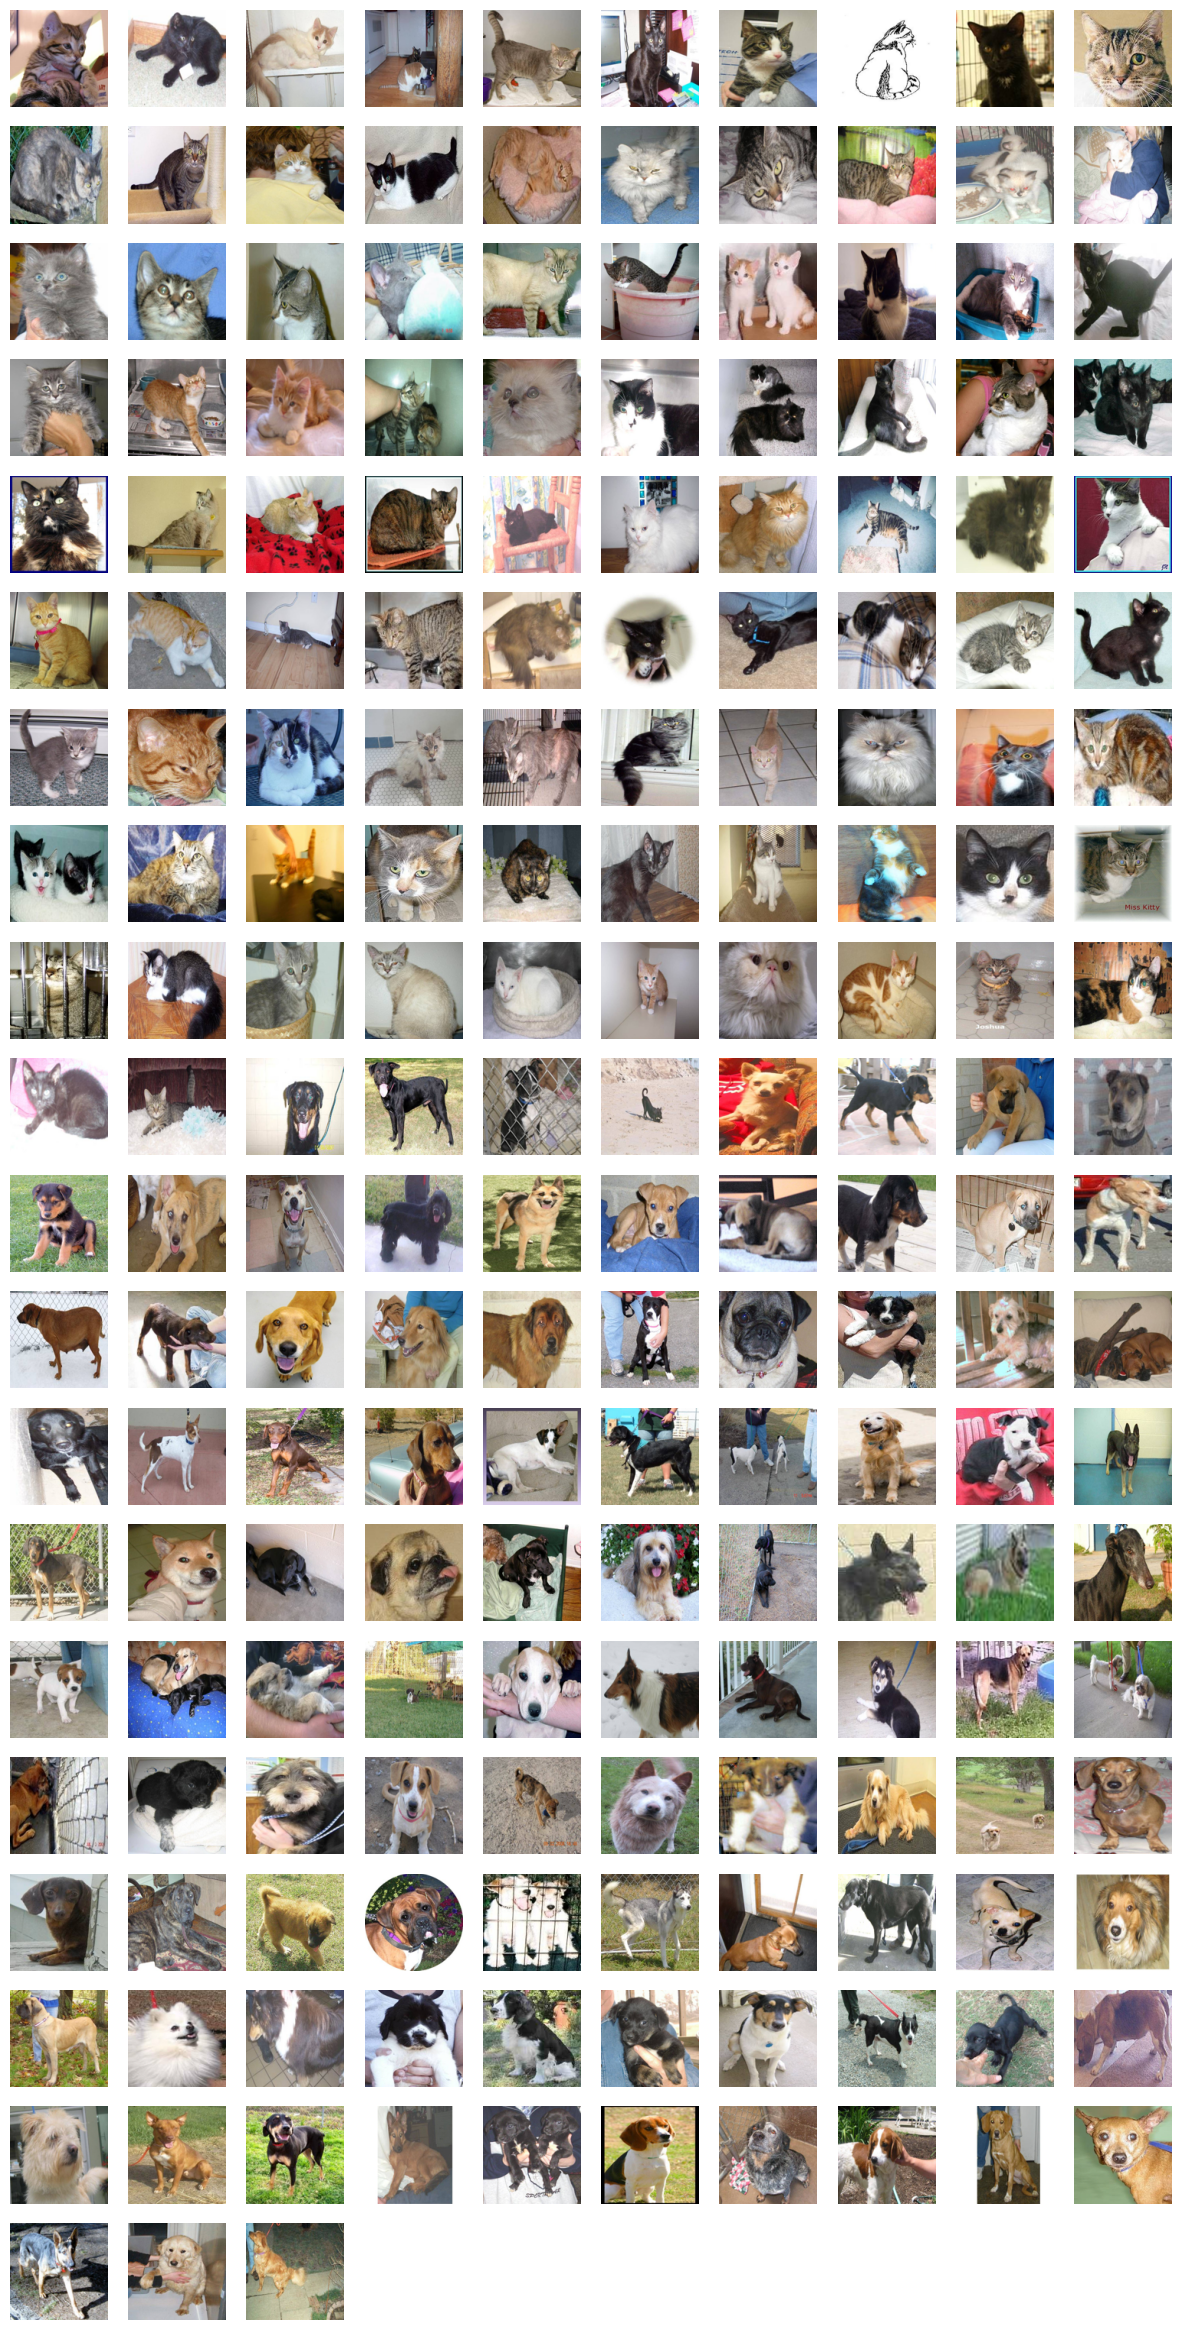

In [15]:
import matplotlib.pyplot as plt
import math

cluster_0_images = images[predicted_clusters == 0]

n = len(cluster_0_images)
cols = 10
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 1.5))
axes = axes.flatten()

for i in range(n):
    axes[i].imshow(cluster_0_images[i])
    axes[i].axis("off")

for i in range(n, len(axes)):
    axes[i].axis("off")

plt.show()